# PTPRB Metrics

In [4]:
from pathlib import Path

from lynceus_core.features import MOLECULAR_FEATURES
from surrogate_model.common.metrics import DEFAULT_EVAL_PERCENTS

from metrics import (
    Panel,
    bedroc_lines,
    compute_gain_curves,
    compute_metrics,
    discover_models,
    fraction_lines,
    load_validation,
    plot_gain_curves,
    plot_metric_panels,
    score_rounds,
)

In [5]:
DATA_ROOT = Path("data/ptprb")
MODELS_DIR = DATA_ROOT / "5-rounds-20k" / "models"
FRACTIONS = sorted(DEFAULT_EVAL_PERCENTS, reverse=True)

In [9]:
validation = load_validation(DATA_ROOT / "validation" / "100k")
scores = score_rounds(discover_models(MODELS_DIR), validation, MOLECULAR_FEATURES)

run = MODELS_DIR.parent.name
results = compute_metrics(run, validation.labels, scores)
curves = compute_gain_curves(run, validation.labels, scores)
results

run,round,recall@1%,ef@1%,recall@5%,ef@5%,recall@10%,ef@10%,recall@25%,ef@25%,BEDROC (80.5),BEDROC (160.9)
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""5-rounds-20k""",1,0.166842,16.69522,0.576076,11.521875,0.782791,7.828159,0.961175,3.844822,0.264005,0.207813
"""5-rounds-20k""",2,0.287513,28.770378,0.651626,13.03294,0.823715,8.237406,0.958027,3.83223,0.398538,0.356769
"""5-rounds-20k""",3,0.284365,28.455374,0.647429,12.948992,0.827912,8.27938,0.965373,3.861612,0.400611,0.35957
"""5-rounds-20k""",4,0.298006,29.820392,0.655824,13.116888,0.824764,8.247899,0.951731,3.807046,0.406473,0.362423
"""5-rounds-20k""",5,0.304302,30.4504,0.656873,13.137875,0.834208,8.342341,0.960126,3.840625,0.409511,0.368761


In [10]:
results_no_bootstrap = results[1:]

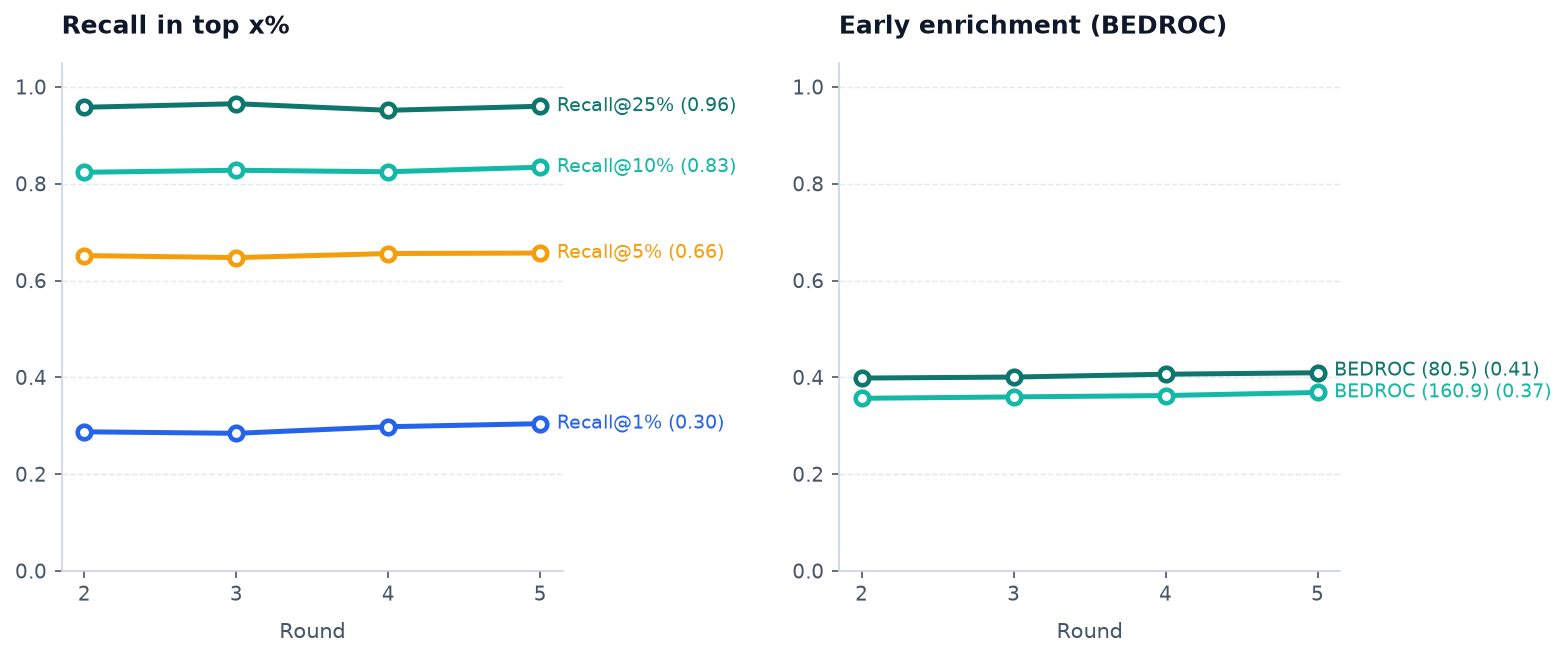

In [11]:
plot_metric_panels(
    results_no_bootstrap,
    [
        Panel("Recall in top x%", fraction_lines("recall", FRACTIONS)),
        Panel("Early enrichment (BEDROC)", bedroc_lines(results)),
    ],
)

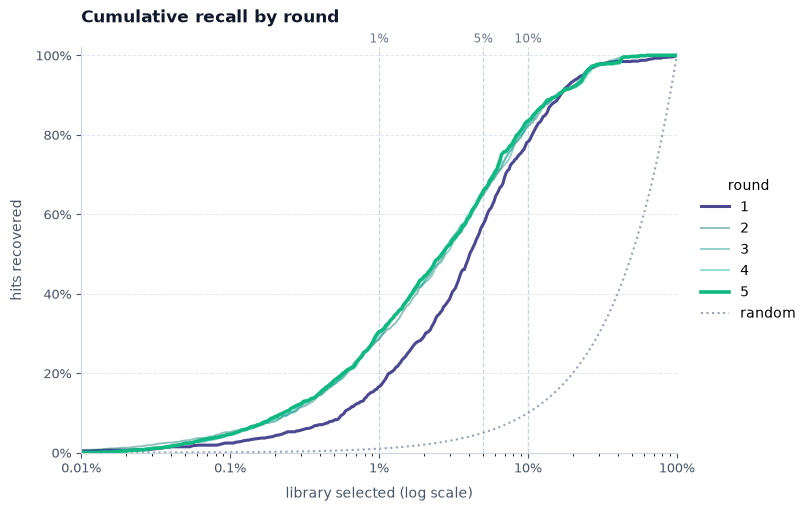

In [8]:
plot_gain_curves(curves)